In [ ]:
import tensorflow as tf
import tensorflow_hub as hub
import pandas as pd
import numpy as np
import os
import datetime
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from IPython.display import Image
import tf_keras

labels_csv = pd.read_csv("/Users/spandankar/Documents/Placement course/AI ML DS/DEEP LEARNING/dog-breed-identification/labels.csv")
print(labels_csv['breed'].value_counts().median())

Image("/Users/spandankar/Documents/Placement course/AI ML DS/DEEP LEARNING/dog-breed-identification/test/0a0b97441050bba8e733506de4655ea1.jpg")

filenames = [f"/Users/spandankar/Documents/Placement course/AI ML DS/DEEP LEARNING/dog-breed-identification/train/{fname}.jpg" for fname in labels_csv["id"]]
labels = np.array(labels_csv["breed"])

unique_breeds = np.unique(labels)
boolean_labels = [label == unique_breeds for label in labels] #One-Hot Encoding

x = filenames
y = boolean_labels

NUM_IMAGES = 1000
np.random.seed(555)
x_train, x_val, y_train, y_val = train_test_split(filenames[:NUM_IMAGES], boolean_labels[:NUM_IMAGES])

82.0


Creating training data batches...
Creating valid data batches...


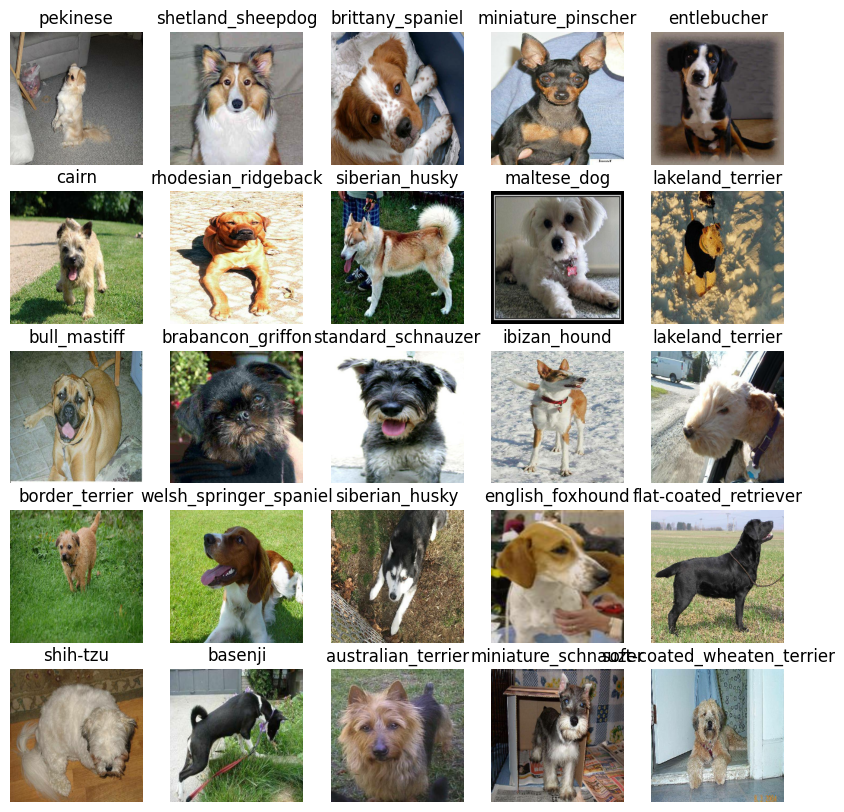

In [15]:
IMAGE_SIZE = 224

def process_image(image_path, image_size=IMAGE_SIZE):
    image = tf.io.read_file(image_path)
    image = tf.image.decode_jpeg(image, channels=3)
    image = tf.image.convert_image_dtype(image, tf.float32)
    image = tf.image.resize(image, size=[image_size, image_size])
    return image

def get_image_label(image_path,label):
    return process_image(image_path),label

BATCH_SIZE = 32

def create_data_batches(x,y=None, batch_size=BATCH_SIZE, valid_data=False, test_data=False):
    if test_data:
        print("Creating test data batches...")
        data = tf.data.Dataset.from_tensor_slices(tf.constant(x))
        data_batch = data.map(process_image).batch(batch_size)
        return data_batch
    
    elif valid_data:
        print("Creating valid data batches...")
        data = tf.data.Dataset.from_tensor_slices((tf.constant(x),tf.constant(y)))
        data_batch = data.map(get_image_label).batch(batch_size)
        return data_batch
    
    else:
        print("Creating training data batches...")
        data = tf.data.Dataset.from_tensor_slices((tf.constant(x),tf.constant(y)))
        data = data.shuffle(buffer_size=len(x))
        data_batch = data.map(get_image_label).batch(batch_size)
        return data_batch

train_data = create_data_batches(x_train, y_train)
val_data = create_data_batches(x_val, y_val, valid_data=True)

def show_25_images(images, labels):
    plt.figure(figsize=(10,10))
    for i in range(25):
        ax = plt.subplot(5,5,i+1)
        plt.imshow(images[i])
        plt.title(unique_breeds[np.argmax(labels[i])])
        plt.axis("off")
    plt.show()

train_images, train_labels = next(train_data.as_numpy_iterator())
show_25_images(train_images, train_labels)

INPUT_SHAPE = [None, 224,224,3]
OUTPUT_SHAPE = len(unique_breeds)
MODEL_URL = 'https://kaggle.com/models/google/mobilenet-v2/TensorFlow2/130-224-classification/1'

def create_model(input_shape=INPUT_SHAPE, output_shape=OUTPUT_SHAPE, model_url=MODEL_URL):
    print("Building model with ",model_url)
    model = tf_keras.Sequential([
        hub.KerasLayer(model_url),
        tf_keras.layers.Dense(output_shape, activation="softmax")
    ])

    model.compile(
        loss=tf_keras.losses.CategoricalCrossentropy(),
        optimizer=tf_keras.optimizers.Adam(),
        metrics=["accuracy"]
    )

    model.build(input_shape)
    return model



In [20]:
def create_tensorboard_callback():
    logdir = os.path.join("/Users/spandankar/Documents/Placement course/AI ML DS/DEEP LEARNING/logs",datetime.datetime.now().strftime("%Y:%m:%d-%H%M%S"))
    return tf_keras.callbacks.TensorBoard(logdir)

early_stopping = tf_keras.callbacks.EarlyStopping(monitor="val_accuracy",patience=3)

NUM_EPOCHS=100

def train_model():
    model = create_model()
    tensorboard = create_tensorboard_callback()
    model.fit(x=train_data, epochs=NUM_EPOCHS, validation_data=val_data, callbacks=[tensorboard, early_stopping])
    
    return model

model = train_model()

print(model.summary())

Building model with  https://kaggle.com/models/google/mobilenet-v2/TensorFlow2/130-224-classification/1


Epoch 1/100
24/24 [==============================] - 7s 247ms/step - loss: 4.4890 - accuracy: 0.1040 - val_loss: 3.3559 - val_accuracy: 0.2600
Epoch 2/100
24/24 [==============================] - 6s 233ms/step - loss: 1.6408 - accuracy: 0.6680 - val_loss: 2.1919 - val_accuracy: 0.4480
Epoch 3/100
24/24 [==============================] - 6s 243ms/step - loss: 0.5881 - accuracy: 0.9213 - val_loss: 1.6481 - val_accuracy: 0.5520
Epoch 4/100
24/24 [==============================] - 6s 249ms/step - loss: 0.2642 - accuracy: 0.9867 - val_loss: 1.4543 - val_accuracy: 0.6280
Epoch 5/100
24/24 [==============================] - 6s 246ms/step - loss: 0.1488 - accuracy: 0.9960 - val_loss: 1.3784 - val_accuracy: 0.6280
Epoch 6/100
24/24 [==============================] - 6s 255ms/step - loss: 0.1015 - accuracy: 1.0000 - val_loss: 1.3340 - val_accuracy: 0.6240
Epoch 7/100
24/24 [==============================] - 47s 2s/step - loss: 0.0762 - accuracy: 1.0000 - val_loss: 1.2951 - val_accuracy: 0.6440
E

In [22]:
predictions = model.predict(val_data, verbose=1)
print(predictions.shape)

8/8 [==============================] - 4s 468ms/step
(250, 120)


In [ ]:
index = 70
print("Max value (Probability of prediction): ",np.max(predictions[index]))
print("Sum: ",np.sum(predictions[index]))
print("Max Index: ",np.argmax(predictions[index]))
print("Predicted Label:", unique_breeds[np.argmax(predictions[index])])


Max value (Probability of prediction):  0.5221369
Sum:  0.9999999
Max Index:  84
Predicted Label: papillon


In [ ]:
def get_pred_label(prediction_probabilities):
    return unique_breeds[np.argmax(prediction_probabilities)]

pred_label = get_pred_label(predictions[10])
print(pred_label)

images = []
labels = []

def unbatchify(data):
    for image,label in data.unbatch().as_numpy_iterator():
        images.append(image)
        labels.append(unique_breeds[np.argmax(label)])
    return images,labels

val_images, val_labels = unbatchify(val_data)

pomeranian


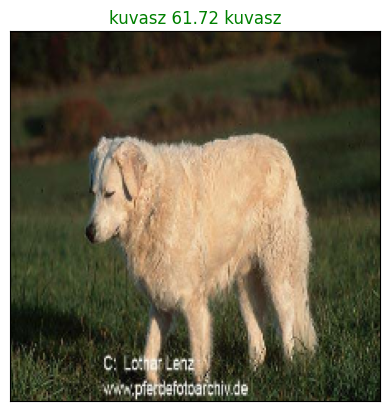

In [40]:
def plot_pred(prediction_probabilities, labels, images, n=8):
    pred_prob = prediction_probabilities[n]
    true_label = labels[n]
    image = images[n]
    pred_label = get_pred_label(pred_prob)
    plt.imshow(image)
    plt.xticks([])
    plt.yticks([])
    if pred_label == true_label:
        color="green"
    else:
        color="red"
    plt.title(f"{pred_label} {np.max(pred_prob) *100:.2f} {true_label}", color=color)

plot_pred(predictions, val_labels, val_images, n=55)



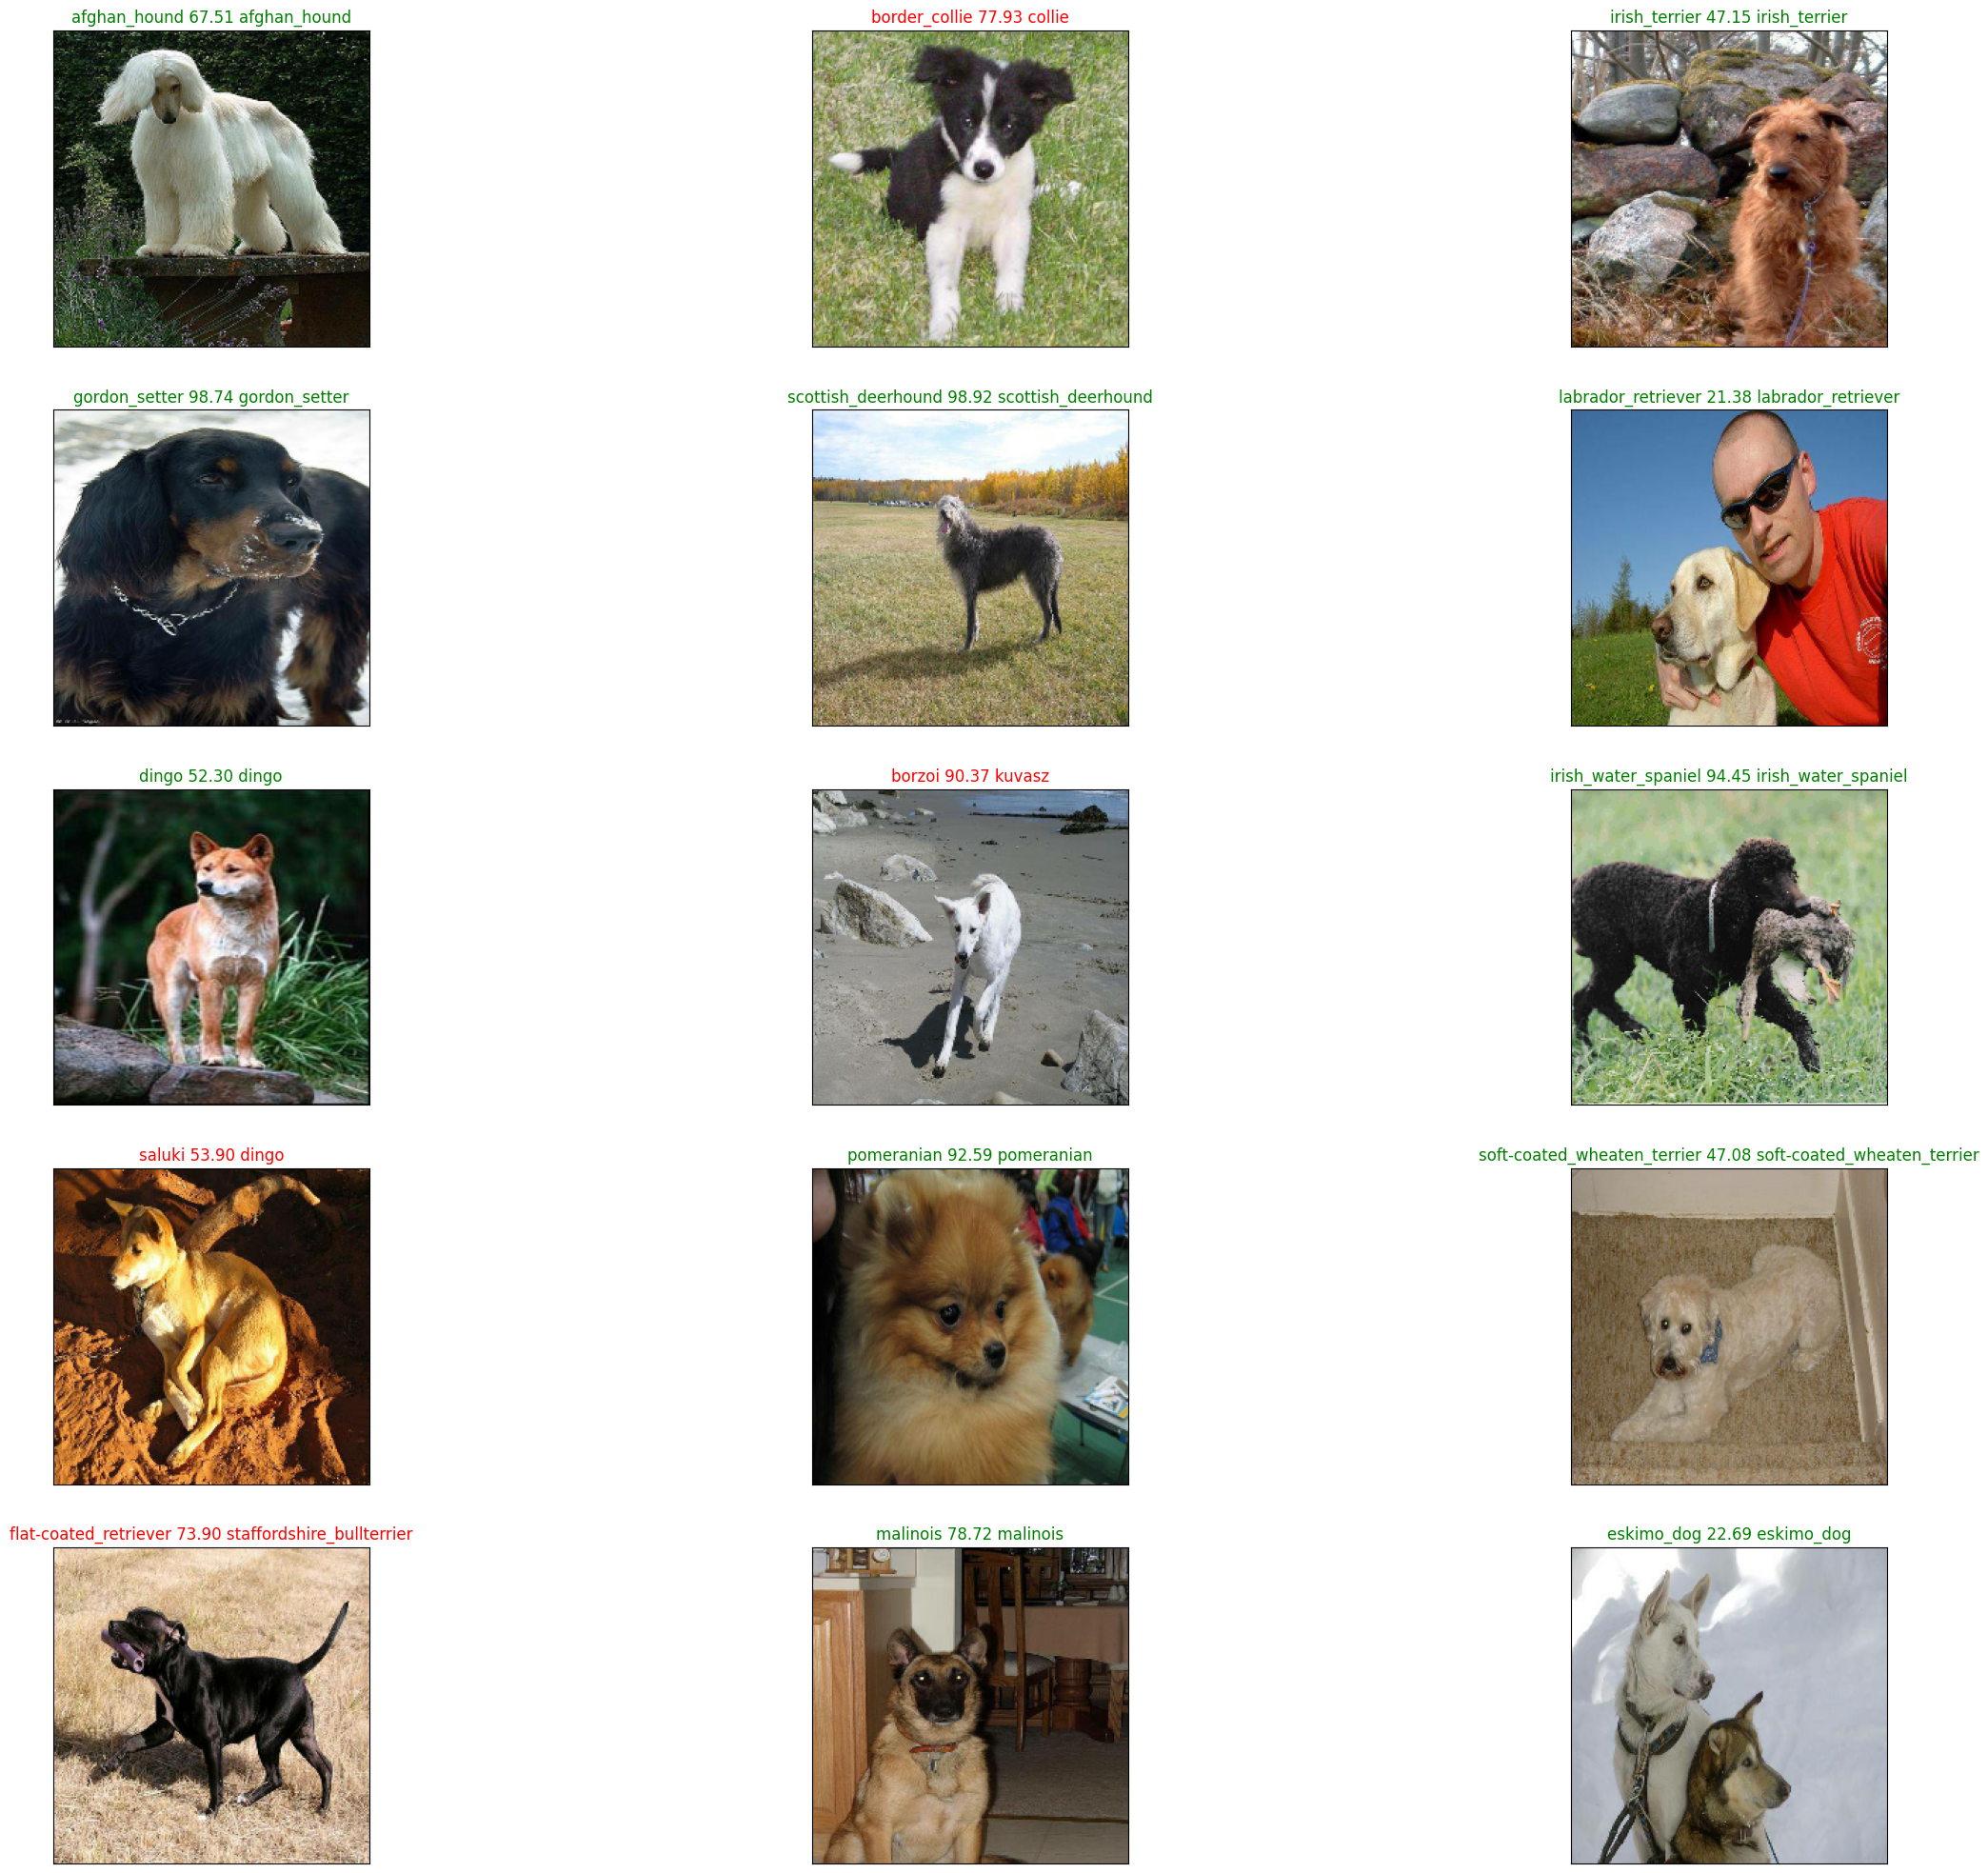

In [43]:
i_mult= 0
num_rows=5
num_cols=3
num_images = num_rows * num_cols
plt.figure(figsize=(10*num_cols, 5*num_rows))

for i in range(num_images):
    plt.subplot(num_rows, 2*num_cols, 2*i+1)
    plot_pred(predictions, val_labels, val_images, i+i_mult)

plt.show()

In [44]:
def save_model(model,suffix=None):
    modeldir = os.path.join("/Users/spandankar/Documents/Placement course/AI ML DS/DEEP LEARNING/models/",
                            datetime.datetime.now().strftime("%Y%m%d-%H%M%S"))
    model_path = modeldir + "-" + suffix + ".h5"
    print(f"Saving model to {model_path}")
    model.save(model_path)
    return model_path

def load_model(model_path):
    print(f"Loading model from {model_path}")
    model = tf_keras.models.load_model(model_path, custom_objects={"KerasLayer":hub.KerasLayer})
    return model

In [45]:
full_data = create_data_batches(filenames, boolean_labels)
full_model = create_model()
full_model_tensorboard = create_tensorboard_callback()
full_model_early_stopping = tf_keras.callbacks.EarlyStopping(monitor="accuracy", patience=3)

full_model.fit(x=full_data, epochs=NUM_EPOCHS, callbacks=[full_model_tensorboard, full_model_early_stopping])
save_model(full_model, "full-image-set-mobilenetV2-Adam")


Creating training data batches...
Building model with  https://kaggle.com/models/google/mobilenet-v2/TensorFlow2/130-224-classification/1


Epoch 1/100
320/320 [==============================] - 59s 182ms/step - loss: 1.3374 - accuracy: 0.6716
Epoch 2/100
320/320 [==============================] - 67s 210ms/step - loss: 0.4030 - accuracy: 0.8800
Epoch 3/100
320/320 [==============================] - 76s 238ms/step - loss: 0.2404 - accuracy: 0.9371
Epoch 4/100
320/320 [==============================] - 78s 243ms/step - loss: 0.1546 - accuracy: 0.9637
Epoch 5/100
320/320 [==============================] - 77s 240ms/step - loss: 0.1072 - accuracy: 0.9794
Epoch 6/100
320/320 [==============================] - 82s 255ms/step - loss: 0.0775 - accuracy: 0.9873
Epoch 7/100
320/320 [==============================] - 82s 257ms/step - loss: 0.0597 - accuracy: 0.9907
Epoch 8/100
320/320 [==============================] - 80s 249ms/step - loss: 0.0464 - accuracy: 0.9950
Epoch 9/100
320/320 [==============================] - 80s 250ms/step - loss: 0.0387 - accuracy: 0.9963
Epoch 10/100
320/320 [==============================] - 80s 249m

/opt/anaconda3/lib/python3.12/site-packages/tf_keras/src/engine/training.py:3098: UserWarning: You are saving your model as an HDF5 file via `model.save()`. This file format is considered legacy. We recommend using instead the native TF-Keras format, e.g. `model.save('my_model.keras')`.
  saving_api.save_model(


'/Users/spandankar/Documents/Placement course/AI ML DS/DEEP LEARNING/models/20250519-210702-full-image-set-mobilenetV2-Adam.h5'

In [46]:
loaded_full_model = load_model("/Users/spandankar/Documents/Placement course/AI ML DS/DEEP LEARNING/models/20250519-20091747665544-full-image-set-mobilenetv2-Adam.h5")

Loading model from /Users/spandankar/Documents/Placement course/AI ML DS/DEEP LEARNING/models/20250519-20091747665544-full-image-set-mobilenetv2-Adam.h5


In [52]:
test_path = "/Users/spandankar/Documents/Placement course/AI ML DS/DEEP LEARNING/dog-breed-identification/test/"
test_filenames = [test_path + fname for fname in os.listdir(test_path)]
test_data = create_data_batches(test_filenames, test_data=True)
test_predictions = loaded_full_model.predict(x=test_data, verbose=1)
np.savetxt("/Users/spandankar/Documents/Placement course/AI ML DS/DEEP LEARNING/dog_preds.txt",test_predictions,delimiter=",")
test_predictions = np.loadtxt("/Users/spandankar/Documents/Placement course/AI ML DS/DEEP LEARNING/dog_preds.txt",delimiter=",")

preds_df = pd.DataFrame(columns=["id"] + list(unique_breeds))
preds_df.head()

Creating test data batches...
324/324 [==============================] - 60s 184ms/step


,id,affenpinscher,afghan_hound,african_hunting_dog,airedale,american_staffordshire_terrier,appenzeller,australian_terrier,basenji,basset,...,toy_poodle,toy_terrier,vizsla,walker_hound,weimaraner,welsh_springer_spaniel,west_highland_white_terrier,whippet,wire-haired_fox_terrier,yorkshire_terrier


In [53]:
test_ids = [os.path.splitext(path)[0] for path in os.listdir(test_path)]
preds_df["id"] = test_ids
preds_df[list(unique_breeds)] = test_predictions
preds_df.head()

,id,affenpinscher,afghan_hound,african_hunting_dog,airedale,american_staffordshire_terrier,appenzeller,australian_terrier,basenji,basset,...,toy_poodle,toy_terrier,vizsla,walker_hound,weimaraner,welsh_springer_spaniel,west_highland_white_terrier,whippet,wire-haired_fox_terrier,yorkshire_terrier
0,266490a2b053a4a3bf68e779f28fb5a9,7.937809e-10,2.703670e-06,2.367426e-08,3.187144e-07,5.885410e-12,1.782897e-06,7.989232e-12,2.988392e-10,9.177137e-04,...,9.635871e-10,2.226337e-09,8.750339e-06,8.187238e-06,1.246548e-06,4.709114e-12,4.267201e-09,5.224887e-06,8.475095e-10,1.120371e-11
1,dae9fd18836d8df20989ef0101771d4b,2.527220e-03,6.368836e-04,4.622644e-06,7.993236e-07,2.477864e-07,3.416497e-08,1.869837e-03,1.621240e-08,8.610823e-08,...,1.616004e-07,3.507454e-06,3.868046e-07,2.041785e-04,9.698713e-05,9.657621e-11,1.485458e-06,1.150815e-06,1.516511e-06,1.446933e-07
2,079a40f22b0fad9a66f76797b62bb930,4.094540e-08,2.381598e-10,7.588397e-12,4.310147e-11,9.461118e-11,1.806041e-11,7.845543e-12,3.350752e-11,7.443356e-12,...,9.415724e-13,4.398668e-12,2.987219e-12,1.189482e-10,3.645896e-11,5.486667e-13,6.173593e-13,1.508775e-12,6.936542e-12,2.345581e-12
3,ab8462f9a501d362041d47582fddc9ad,2.466211e-09,2.400482e-08,2.520996e-12,1.386079e-08,6.858061e-12,6.873397e-08,5.083322e-09,1.069889e-11,1.774991e-09,...,2.745690e-09,9.534824e-10,5.484315e-10,6.957191e-08,2.260033e-10,5.428514e-07,1.706604e-09,1.165588e-10,9.421304e-12,6.690337e-07
4,8895089b432e020cc42e6262b5a1c2dd,1.677212e-10,1.103175e-09,6.028413e-09,2.200443e-11,8.255359e-09,4.817347e-09,1.915704e-07,5.311253e-04,4.019075e-06,...,1.805469e-09,5.619648e-08,3.846015e-10,5.535756e-11,4.165575e-10,2.806165e-08,9.939837e-09,1.792505e-07,3.313269e-08,8.365301e-12


In [54]:
preds_df.to_csv("/Users/spandankar/Documents/Placement course/AI ML DS/DEEP LEARNING/full_model_submission.csv")

In [55]:
custom_path = "/Users/spandankar/Documents/Placement course/AI ML DS/DEEP LEARNING/Dog Photos/"
custom_image_paths = [custom_path + fname for fname in os.listdir(custom_path)]
custom_data = create_data_batches(custom_image_paths, test_data=True)
custom_preds = loaded_full_model.predict(custom_data)

Creating test data batches...
1/1 [==============================] - 0s 155ms/step


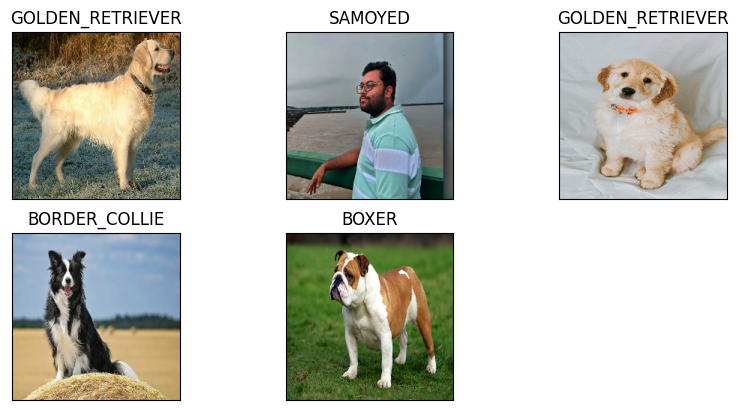

In [60]:
custom_labels = [get_pred_label(custom_preds[i]) for i in range(len(custom_preds))]
custom_images = []

for image in custom_data.unbatch().as_numpy_iterator():
    custom_images.append(image)

plt.figure(figsize=(10,10))

for i,image in enumerate(custom_images):
    plt.subplot(4,3,i+1)
    plt.xticks([])
    plt.yticks([])
    plt.title(custom_labels[i].upper())
    plt.imshow(image)
plt.show()